# Sabotage Connectome

`wCSET` uses a structural connectome as a prior (via the Laplacian spectrum -- see `mm.analysis.connectivity.compute_cst`), which is never perfectly known in practice. This notebook measures how much reconstruction accuracy degrades as that connectome is corrupted, comparing 3 independent corruption methods side by side (see the "Three corruption methods" section below for what each represents): `swap_rewire_connectome` (degree-preserving rewiring), and two variants of `perturb_connectome_topology` (independent random edge deletion/addition) -- one uniform ("brutal"), one spatially biased to mimic real dMRI/tractography error structure ("dmri").

Uses simulated data (`simf10`) specifically because it has a known ground truth (`gold`) -- degradation is only cleanly measurable against a known answer.

**Runtime note**: each connectome's Laplacian eigendecomposition (`compute_cst`) takes ~17-20s on this connectome's size (~7500 nodes, dense `eigh`). With 3 methods x 6 severity levels x 5 repeats (minus the redundant 0%-repeats, identical across methods/seeds and reused once), that's ~76 real decompositions -- expect this notebook to take on the order of 20-25 minutes end-to-end (the corruption methods themselves are all negligible, well under a minute total across the whole notebook; the eigendecompositions dominate).

## 🧪 - Experiment setup
- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance
- `con`: Structural connectome (raw, before any weight transform or sabotage)
- `gold`: Ground truth

In [1]:
# imports
import numpy as np
from tqdm import tqdm

import mindmap as mm

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
run = "24"

# data
fwd = dm.load(sub, "fwd", desc="inv")
ave = dm.load(sub, "ave", run=run)
ncov = dm.load(sub, "cov", run=run)
con = dm.load(sub, "con")
gold = dm.load(sub, "gold", run=run)

# crop
tmin, tmax = -0.05, 0.15

## 🧬 - Data Processing
Estimate regularization parameter

In [2]:
snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=(-0.4, -0.2), noise_cov=ncov)
lambda2 = 1.0 / (snr.max()**2)

print(f"Estimated SNR: {snr.max():.3f}")
print(f"Estimated lambda2: {lambda2:.3f}")

# cap the regularization parameter. Smaller values don't regularize anymore.
lambda2 = max(0.01, lambda2)

    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 4.1e-15 (2.2e-16 eps * 203 dim * 0.09  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
    Created the whitener using a noise covariance matrix with rank 202 (1 small eigenvalues omitted)
Estimated SNR: 25.619
Estimated lambda2: 0.002


In [3]:
data = ave.copy().crop(tmin=tmin, tmax=tmax)
ground = gold.copy().crop(tmin=tmin, tmax=tmax)

# ground-truth phases: half-rising-phase and peak-phase sample indices --
# same mechanism inverse-simf.ipynb uses for its precision-recall metrics.
# Evaluating correlation at just these 2 timepoints (rather than the full
# ~50-sample window) keeps the sweep's plot readable -- 3 methods x 6
# severity levels x 5 repeats would be unreadable as full time-series curves.
hrp = mm.analysis.eeg.get_rising_phase(data, ratio=0.5, as_idx=True)[0]
pp = mm.analysis.eeg.get_rising_phase(data, ratio=1, as_idx=True)[0]

# Weight inversion (length -> strength) is a semantic decision about what
# the connectome's weights mean, not part of compute_cst's job -- done once
# here, before any sabotage draw, not inside compute_cst itself.
con_strength = np.divide(1, con, out=np.zeros_like(con), where=con > 0)

# dipole coordinates for the dMRI-realistic corruption method below.
source_space = fwd["src"]

## 🎚️ - Three corruption methods, calibrated to a common severity axis

Three independent ways of getting the structural connectome prior "wrong", compared
side by side:
- **`swap`** (`mm.analysis.connectivity.swap_rewire_connectome`): degree- and
  edge-count-*preserving* random rewiring -- the topology is shuffled but the
  connectome's coarse statistics stay correct. Its swap-count -> corruption curve
  saturates *below* 100% (a freshly rewired graph is expected to share a few edges
  with the original by chance, at this density -- see its docstring) and isn't
  linear, so it needs empirical calibration (probe a swap-count grid, invert the
  curve) to land on genuinely-spaced 20/40/60/80/100% severity levels.
- **`brutal`** (`mm.analysis.connectivity.perturb_connectome_topology`, uniform
  sampling): the roughest plausible corruption -- independent random edge deletions
  and additions, uniformly distributed, with no attempt to preserve degree or any
  other structure. Unlike `swap`, deletions and additions are drawn from disjoint
  pools (an existing-edge pool and a non-edge pool), so `n_additions / total_edges`
  is *exactly* the fraction of new edges -- no calibration curve needed, just
  `n_deletions = n_additions = round(percentage/100 * total_edges)`.
- **`dmri`** (`perturb_connectome_topology` again, now with
  `mm.analysis.connectivity.dmri_uncertainty_weights_from_source_space`'s
  distance-biased sampling weights): mimics real tractography error structure
  instead of uniform randomization -- false positives (additions) biased toward
  short, geometrically-plausible pairs, false negatives (deletions) biased toward
  long-range pairs, and more additions than deletions (`DMRI_ADDITION_RATIO`, a
  starting point from Maier-Hein et al. 2017's false-positive-dominant finding, not
  a fitted constant). Same exact-fraction property as `brutal`, just asymmetric.

In [4]:
percentages = [0, 20, 40, 60, 80, 100]
n_repeats = 5
methods = ["swap", "brutal", "dmri"]
DMRI_ADDITION_RATIO = 2   # additions:deletions -- see markdown above

triu_idx = np.triu_indices_from(con_strength, k=1)
orig_vals = con_strength[triu_idx]
orig_edges = orig_vals != 0
total = int(orig_edges.sum())

# --- swap: probe a swap-count grid, invert the curve to hit pct/100 * ceiling.
def measure_swap_binary_frac(mult, seed=0):
    n_swaps = round(mult * total / 2)
    rewired = mm.analysis.connectivity.swap_rewire_connectome(con_strength, n_swaps=n_swaps, seed=seed)
    return ((rewired[triu_idx] != 0) & ~orig_edges).sum() / total

mult_grid = np.array([0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1, 1.5, 2, 3, 4, 5, 7, 10, 13, 16, 20, 25, 30])
probe_fracs = np.array([measure_swap_binary_frac(mult) for mult in mult_grid])
probe_fracs_mono = np.maximum.accumulate(probe_fracs)  # enforce monotonic, needed for interpolation
swap_ceiling = probe_fracs_mono[-1]

calibrated_n_swaps = {0: 0}
for percentage in percentages[1:]:
    target_frac = percentage / 100 * swap_ceiling
    mult = np.interp(target_frac, probe_fracs_mono, mult_grid)
    calibrated_n_swaps[percentage] = round(mult * total / 2)

# --- brutal / dmri: exact closed form, no probing needed (see markdown above).
brutal_counts = {p: round(p / 100 * total) for p in percentages}
dmri_counts = {p: (round(brutal_counts[p] / DMRI_ADDITION_RATIO), brutal_counts[p]) for p in percentages}  # (n_deletions, n_additions)

deletion_weights, addition_weights = mm.analysis.connectivity.dmri_uncertainty_weights_from_source_space(con_strength, source_space)

print(f"swap_rewire_connectome empirical ceiling (treated as '100%'): {swap_ceiling:.4f}")
print(f"calibrated n_swaps per severity level: {calibrated_n_swaps}")
print(f"brutal n_deletions=n_additions per severity level: {brutal_counts}")
print(f"dmri (n_deletions, n_additions) per severity level: {dmri_counts}")


def corrupt(method, percentage, seed):
    if method == "swap":
        return mm.analysis.connectivity.swap_rewire_connectome(con_strength, n_swaps=calibrated_n_swaps[percentage], seed=seed)
    if method == "brutal":
        k = brutal_counts[percentage]
        return mm.analysis.connectivity.perturb_connectome_topology(con_strength, n_deletions=k, n_additions=k, seed=seed)
    if method == "dmri":
        n_del, n_add = dmri_counts[percentage]
        return mm.analysis.connectivity.perturb_connectome_topology(
            con_strength, n_deletions=n_del, n_additions=n_add,
            deletion_weights=deletion_weights, addition_weights=addition_weights, seed=seed,
        )
    raise ValueError(f"unknown method {method!r}")

swap_rewire_connectome empirical ceiling (treated as '100%'): 0.9890
calibrated n_swaps per severity level: {0: 0, 20: 24335, 40: 55744, 60: 101659, 80: 182560, 100: 3274785}
brutal n_deletions=n_additions per severity level: {0: 0, 20: 43664, 40: 87328, 60: 130991, 80: 174655, 100: 218319}
dmri (n_deletions, n_additions) per severity level: {0: (0, 0), 20: (21832, 43664), 40: (43664, 87328), 60: (65496, 130991), 80: (87328, 174655), 100: (109160, 218319)}


## 💥 - Sabotage sweep

Runs `wCSET` on all `methods` x `percentages` x `n_repeats` corrupted connectomes.
Each draw is registered under its method name as the metric's `Label` (`MetricSuite`'s
default grouping column), so the plot below separates the 3 methods by color
automatically, no extra plotting code needed.

`wCSET` only for now -- `CSET`'s per-timepoint iterative solve is much more expensive
and is deliberately out of scope while this pipeline is still being set up.

In [5]:
metrics = mm.metric.MetricSuite(f"Sabotage Connectome {sub}")

# percentage=0 is a no-op for all 3 methods and every seed (each is a documented
# no-op at zero severity) and gives the identical clean con_strength regardless of
# method -- compute its spectrum once and reuse everywhere, instead of paying for
# 3 methods x 5 identical (and expensive, ~20s each) eigendecompositions.
eigvec_clean, eigval_clean = mm.analysis.connectivity.compute_cst(con_strength)

for method in methods:
    for percentage in tqdm(percentages, desc=f"{method} severity levels"):
        for repeat in range(n_repeats):
            if percentage == 0:
                eigvec, eigval = eigvec_clean, eigval_clean
            else:
                sabotaged = corrupt(method, percentage, repeat)
                eigvec, eigval = mm.analysis.connectivity.compute_cst(sabotaged)

            inv = mm.analysis.inverse.wCSET(
                forward = fwd,
                noise_cov = ncov,
                depth = 0.5,
                eigenvectors = eigvec,
                eigenvalues = eigval,
                harm = 0.8,
            )
            sol = inv.solve(data, lambda2)

            corr = np.asarray(mm.analysis.inverse.compute_stc_correlation(ground, sol, mode="spatial", method="pearson"))

            metrics.register(method, "correlation_hrp", float(corr[hrp]), percentage=percentage)
            metrics.register(method, "correlation_pp", float(corr[pp]), percentage=percentage)

dmri severity levels: 100%|██████████| 6/6 [09:00<00:00, 90.09s/it] 


## 📊 - Visualization

Correlation vs. connectome corruption severity, at the half-rising-phase and peak-phase timepoints, one colored line per corruption method (`swap`/`brutal`/`dmri`). The shaded band is the confidence interval computed automatically from the 5 repeats at each severity level.

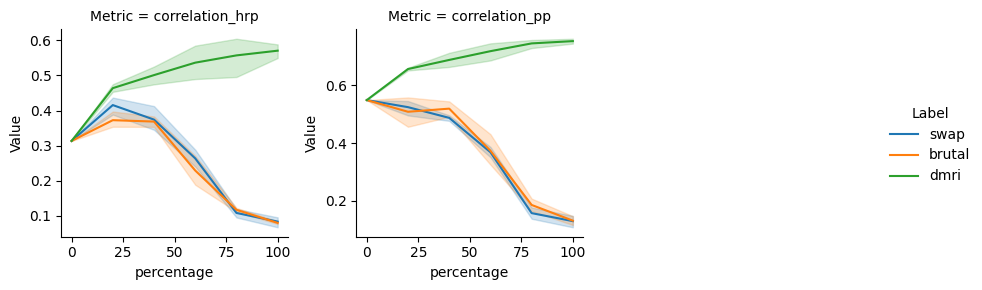

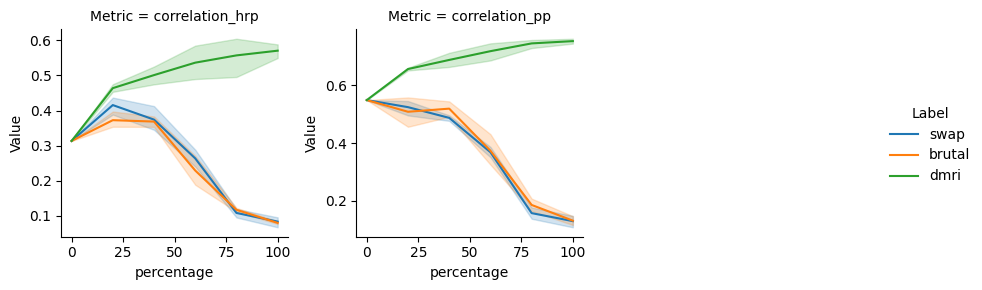

In [7]:
metrics.plot(
    metrics = ["correlation_hrp", "correlation_pp"],
    coord = "percentage",
    kind = "line",
)

In [9]:
mm.viz.plot_brain_activity(fwd["src"], [sol, ground], func_params={"absolute":True, "normalize":"max"}).show()

/home/nino/Code/mindmap/mindmap/viz/vista.py:85: UserWarning: Inconsistent time vectors detected across meshes. Using the first available.
  warnings.warn("Inconsistent time vectors detected across meshes. Using the first available.")


Widget(value='<iframe src="http://localhost:42547/index.html?ui=P_0x7c2d5ae49d10_1&reconnect=auto" class="pyvi…